### MoE Transformer Model for Predicting Returns

### New and more comprehensive baseline models
#### 1. GARCH
#### 2. PCR
#### 3. PLS
#### 4. GLM

In [1]:
!pip install arch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.3/981.3 kB 19.5 MB/s eta 0:00:00


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from typing import List, Tuple, Optional, Union, Any
from dataclasses import dataclass
from tqdm import tqdm
import logging
from datetime import date, timedelta
from torchinfo import summary
import os
import math
import statsmodels.api as sm
import random
from sklearn.preprocessing import StandardScaler
from arch import arch_model
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

import matplotlib.pyplot as plt


# arch_model v4.19 or later

logging.basicConfig(level=logging.DEBUG, format="%(asctime)s - %(levelname)s - %(message)s")
logger = logging.getLogger("RetPredictor")

def set_seed(seed: int = 32) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()


class WeightedMSELoss(nn.Module):
    def forward(self, input, target, weight):
        return (weight * (input - target) ** 2).mean()

class PriceReturnDataset(torch.utils.data.Dataset):
    def __init__(self, 
                 seq_len: int,
                 n_pred: int,
                 df: pd.DataFrame, 
                 features: List[str], 
                 targets: np.ndarray,
                 prob_col: Optional[str]=None,
                 n_regimes: int=2,
                 is_test: bool=False,
                ) -> None:
        self.seq_len = seq_len
        self.n_pred = n_pred
        self.df = df
        self.targets = targets
        self.features = features
        self.prob_col = prob_col
        self.n_regimes = n_regimes
        self.is_test = is_test
        ndays = df.shape[0]
        assert ndays == targets.shape[0], "Mismatch in df shape and targets shape"

    def __len__(self) -> int:
        if self.is_test:
            return (self.targets.shape[0] - self.seq_len + 1) // self.n_pred
        return self.targets.shape[0] - self.seq_len - self.n_pred + 1

    def __getitem__(self, idx: int) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
        if self.is_test:
            begin = idx*self.n_pred
            end = idx*self.n_pred +self.seq_len-1
        else:
            begin = idx
            end = idx+self.seq_len-1
        data_array = self.df.loc[begin:end, self.features].values # pd includes both start and begin
        ar_pred = self.df.loc[end:end+self.n_pred-1, "arPred"].values
        # (seq_len, nfeatures)
        if self.prob_col is None:
            cols = [f"p{i}" for i in range(self.n_regimes)]
            prob_array = self.df.loc[end:end+self.n_pred-1, cols].values
        else:
            prob_array = self.df.loc[end:end+self.n_pred-1, self.prob_col].values
        return (
            torch.tensor(data_array, dtype=torch.float32),
            self.targets[end:end+self.n_pred],
            torch.tensor(prob_array, dtype=torch.float32),
            torch.tensor(ar_pred, dtype=torch.float32),
        )

    
class SimpleDataset(torch.utils.data.Dataset):
    def __init__(self,
                 X: np.ndarray,
                 y: np.ndarray,
                 seq_len: int = 0,
                ) -> None:
        self.X = X
        self.y = y
        self.seq_len = seq_len
        assert self.X.shape[0] == self.y.shape[0], "Shapes must have equal number of rows"
        
    def __len__(self) ->  int:
        if self.seq_len:
            return self.X.shape[0] - self.seq_len + 1
        return self.X.shape[0]
    
    def __getitem__(self, idx: int) -> Tuple[np.ndarray, float]:
        if self.seq_len:
            return self.X[idx:idx+self.seq_len, :], self.y[idx]
        return self.X[idx, :], self.y[idx]
    
    
class PositionalEncoding(nn.Module):
    def __init__(self, seq_len: int, d_model: int) -> None:
        super().__init__()
        pe = torch.zeros(seq_len, d_model)
        pos = torch.arange(0, seq_len).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(pos * div_term)
        pe[:, 1::2] = torch.cos(pos * div_term)

        self.pe = pe.unsqueeze(0)  # (1, seq_len, d_model)

    def forward(self, x: torch.tensor) -> torch.tensor:
        return x + self.pe[:, 0:x.size(1), :].to(x.device)


class EncoderPredictor(nn.Module):
    def __init__(self, 
                 n_features: int,
                 seq_len: int,
                 ret_index: int,
                 d_model: int=64, 
                 n_head: int=4, 
                 n_layers: int=2, 
                 dropout: float=0.1,
                 n_pred: int=10, #10,
                ) -> None:
        super().__init__()
        self.n_features = n_features
        self.seq_len = seq_len
        self.ret_index = ret_index

        self.relu = nn.ReLU()
        
        # Project features → model dimension
        self.input_projection = nn.Linear(n_features, d_model)

        # Positional encoding
        self.pos_encoding = PositionalEncoding(seq_len=seq_len, d_model=d_model)

        # Transformer Encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_head,
            dropout=dropout,
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)

        # Output head
        self.fc1 = nn.Sequential(
            nn.Linear(d_model, 32),
            self.relu,
            nn.Linear(32, 1),
        )

        self.fc2 = nn.Sequential(
            nn.Linear(seq_len, 32),
            self.relu,
            nn.Linear(32, n_pred),
        )

        self.n_autoreg_returns = min(3, seq_len)
        self.fc_final = nn.Linear(self.n_autoreg_returns + n_pred, n_pred)
        
        # print a summary of the model
        logger.info(self.summary())

    def forward(self, x_input: torch.tensor) -> torch.tensor:
        # x: (B, T, F) where T: seq_len, F: num features
        x = self.input_projection(x_input)

        # Add positional encoding
        x = self.pos_encoding(x)

        # Transformer
        x = self.transformer(x)

        # predict output
        x = self.fc1(x)

        x = torch.squeeze(x, 2)
        x = self.fc2(x)

        x_final = torch.cat((x_input[:, x_input.shape[1]-self.n_autoreg_returns:, self.ret_index], 
                             x), dim=1)
        x_out = self.fc_final(x_final)

        return x_out
    
    def summary(self) -> None:
        model_stats = summary(self, input_size=(1, self.seq_len, self.n_features))
        logger.info(f"Total trainable parameters: {model_stats.trainable_params}")
    

class NNPredictor(nn.Module):
    """ A simple neural network predictor model for baseline comparison """
    def __init__(self, n_features: int) -> None:
        super().__init__()
        self.n_features = n_features
        self.layer1 = nn.Linear(n_features, 32)
        self.gelu = nn.GELU()
        self.layer2 = nn.Linear(32, 64)
        self.layer3 = nn.Linear(64, 32)
        self.layer4 = nn.Linear(32, 1)
        self.summary()
        
    def forward(self, x_input: torch.tensor) -> torch.tensor:
        x1 = self.layer1(x_input)
        x1 = self.gelu(x1)
        x1 = self.layer2(x1)
        x1 = self.gelu(x1)
        x1 = self.layer3(x1)
        x1 = self.gelu(x1)
        x1 = self.layer4(x1)
        return x1
    
    def summary(self) -> None:
        model_stats = summary(self, input_size=(1, self.n_features))
        logger.info(f"Total trainable parameters: {model_stats.trainable_params}")
        
        
class LSTMPredictor(nn.Module):
    def __init__(self, 
                 n_features: int, 
                 hidden_size: int, 
                 n_layers: int,
                ) -> None:
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden_size, n_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)
        
    def forward(self, x: torch.tensor) ->  torch.tensor:
        # Forward pass: pass only last hidden state to linear layer
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])
    

class LearnedVolatilityGate(nn.Module):
    def __init__(self, n_features: int, n_experts: int) -> None:
        super().__init__()
        self.linear = nn.Linear(n_features, n_experts)
        self.softmax = nn.Softmax(n_experts)
        
    def forward(self, x: torch.tensor) -> torch.tensor:
        signal = self.linear(x)
        return self.softmax(signal)
    
@dataclass
class ModelConfig:
    use_gpu: bool = True
    src_seq_len: int = 21
    d_model: int = 64 #32 #96 #128 #64
    n_head: int = 8
    n_layer: int = 12
    n_pred: int = 1
    n_regimes: int = 2
    p_dropout: float = 0.1
    learning_rate: float = 0.002
    weight_decay: float = 0.01
    betas: Tuple[float, float] = (0.9, 0.999)
    n_epochs: int = 15
    batch_size: int = 32
    shuffle: bool = False
    max_grad_norm: float = 1.0
    save_model: bool = False
    features: Tuple[str] = ("retPeriod",
                            "priceConvexity",
                            "volatility1Month", 
                            "longShortMA",
                            "mfi",
                            "rsi",
                            "px_mom",
                            "DGS30",
                            "Yield30YChg",
                            "T10Y3M",
                           )
    
    ret_index: int = 0 # index of retPeriod in features
    float_dtype = torch.float32
    use_sampling: bool = False
    learned_volatility_gate: bool = False
        
    # lags used in AR model
    n_lags: int = 3
        
    # trade strat paramss
    train_begin_dt: date = date(2000, 2, 4)
    train_end_dt: date = date(2017, 3, 1)
        
    # for data
    input_dir: str = "/kaggle/input/datasets/samitahlawat/stockeoddata/stocks"
    spy_input_dir: str = "/kaggle/input/datasets/samitahlawat/stockeoddata"
    mev_input_dir: str = "/kaggle/input/datasets/samitahlawat/stockeoddata/mev"
    output_dir: str = "/kaggle/working"
        
class ModelContainer:
    def __init__(self, config: ModelConfig, device: torch.device) -> None:
        self.device = device
        self.config = config
        self.model = EncoderPredictor(n_features=len(config.features),
                                      seq_len=config.src_seq_len,
                                      ret_index=config.ret_index,
                                      d_model=config.d_model,
                                      n_head=config.n_head, 
                                      n_layers=config.n_layer,
                                      dropout=config.p_dropout,
                                      n_pred=config.n_pred,
                                     ).to(self.device)
        self.loss_fn = WeightedMSELoss().to(self.device).to(config.float_dtype)
        self.optimizer = optim.AdamW(self.model.parameters(), 
                                     lr=config.learning_rate,
                                     betas=config.betas, 
                                     weight_decay=config.weight_decay)
        self.scheduler = optim.lr_scheduler.ReduceLROnPlateau(self.optimizer,
                                                              mode='min',
                                                              factor=0.1, 
                                                              patience=3,
                                                             )

    def finetune_one_epoch_using_data(self, x: torch.tensor, y: torch.tensor, weight: torch.tensor) -> float:
        self.model.train()
        self.optimizer.zero_grad()
        encoder_input = x.to(self.device).to(self.config.float_dtype) # (b, seq, nfeatures)
        tgt = y.to(self.device).to(self.config.float_dtype)
        wgt = weight.to(self.device).to(self.config.float_dtype)
        pred = self.model(encoder_input)

        # Compute the loss
        loss = self.loss_fn(pred, tgt, wgt)

        # Backpropagate the loss
        loss.backward()

        # Update the weights
        self.optimizer.step()
        
        total_loss = loss.item()
        self.model.eval()
        return total_loss
    
    def train_one_epoch(self, epoch: int, dataloader: torch.utils.data.DataLoader) -> float:
        batch_iterator = tqdm(dataloader, desc=f"Processing Epoch {epoch:02d}")
        total_loss = 0.0
        for batch in batch_iterator:
            self.optimizer.zero_grad()
            encoder_input = batch[0].to(self.device).to(self.config.float_dtype) # (b, seq, nfeatures)
            tgt = batch[1].to(self.device).to(self.config.float_dtype)
            prob = batch[2].to(self.device).to(self.config.float_dtype)
            pred = self.model(encoder_input)

            # Compute the loss
            loss = self.loss_fn(pred, tgt, prob)

            # Backpropagate the loss
            loss.backward()

            # Update the weights
            self.optimizer.step()
            
            total_loss += loss.item()
        return total_loss / len(dataloader)
        
    def train(self, dataset: PriceReturnDataset) -> None:
        dataloader = torch.utils.data.DataLoader(
            dataset=dataset,
            batch_size=self.config.batch_size,
            shuffle=self.config.shuffle,
            drop_last=False,
        )
        loss_arr = []
        lr_arr = []
        self.model.train()
        
        for epoch in range(self.config.n_epochs):
            loss = self.train_one_epoch(epoch, dataloader)
            
            self.scheduler.step(loss)
        
            logger.info(
                f"Epoch [{epoch+1}/{self.config.n_epochs}] "
                f"Loss: {loss:.4f} "
                f"LR = {self.optimizer.param_groups[0]['lr']}"
            )
            loss_arr.append(loss)
            lr_arr.append(self.optimizer.param_groups[0]['lr'])
            
        # set to eval mode after training
        self.model.eval()
        logger.info(loss_arr)
        logger.info(lr_arr)

    def save(self, name: str) -> None:
        model_filename = os.path.join(self.config.output_dir, f"{name}.pth")
        torch.save({
            'model_state_dict': self.model.state_dict(),
        }, model_filename)
        
    def load(self, name: str) -> None:
        model_filename = os.path.join(self.config.output_dir, f"{name}.pth")
        checkpoint = torch.load(model_filename, map_location=self.device)
        self.model.load_state_dict(checkpoint)
        self.model.eval()
        
    @torch.no_grad()
    def predict(self, x: torch.tensor) -> torch.tensor:
        x = x.to(self.device).to(self.config.float_dtype)
        return self.model(x)

    
class FeatureCalculator:
    @staticmethod
    def adjustPrices(df: pd.DataFrame) -> pd.DataFrame:
        df.loc[:, "Adj Close"] = np.where(df.loc[:, "Adj Close"].isna().values, 
                                          df.loc[:, "Close"].values,
                                          df.loc[:, "Adj Close"].values)
        return df
    
    @staticmethod
    def pcrPred(df: pd.DataFrame,
                features: List[str],
                ycol: str,
                begin: int,
                end: int,
                output_colname: str,
                variance_explained: float=0.95,
               ) -> pd.DataFrame:
        # features are already standardized
        X = df.loc[begin:end-1, features].values
        y = df.loc[begin:end-1, ycol].values
        
        pcr_model = Pipeline([
            ("pca", PCA(n_components=variance_explained)),
            ("regression", LinearRegression()),
        ])
        
        pcr_model = pcr_model.fit(X, y)
        
        Xall = df.loc[begin:, features].values
        ypred = pcr_model.predict(Xall)
        df.loc[begin:, output_colname] = ypred
        
        y_test = df.loc[end:, ycol].values
        y_pred_test = ypred[end-begin:]
        
        logger.info(f"PCR R2 Score: {r2_score(y_test, y_pred_test):.3f}")
        logger.info(f"PCR MSE: {mean_squared_error(y_test, y_pred_test):.3f}")
        
        return df
    
    @staticmethod
    def plsPred(df: pd.DataFrame,
                features: List[str],
                ycol: str,
                begin: int,
                end: int,
                output_colname: str,
               ) -> pd.DataFrame:
        # Partial least squares
        # features are already standardized
        
        param_grid = {'n_components': np.arange(1, len(features) + 1, 1)}
        kfold_cv = KFold(n_splits=5, shuffle=False)
        grid_search = GridSearchCV(
            estimator=PLSRegression(),
            param_grid=param_grid,
            cv=kfold_cv,
            scoring="neg_mean_squared_error",
        )
        
        X = df.loc[begin:end-1, features].values
        y = df.loc[begin:end-1, ycol].values
        
        grid_search.fit(X, y)
        
        order = grid_search.best_params_["n_components"]
        cv_mse = -grid_search.cv_results_["mean_test_score"]
        
        logger.info(f"Number of PLS components: {order}")
        
        plt.figure(figsize=(8, 5))
        plt.plot(param_grid['n_components'], cv_mse, marker='o', linestyle='-', color='b')
        plt.axvline(order, color='r', linestyle='--', label=f'Best Order ({order})')
        plt.xlabel('Number of PLS Components')
        plt.ylabel('Cross-Validation MSE')
        plt.title('PLS Order Selection via Cross-Validation')
        plt.legend()
        plt.grid(True)
        plt.savefig("PLSOrderSelection.jpg", dpi=500)
        
        pls_model = PLSRegression(n_components=order)
        
        pls_model = pls_model.fit(X, y)
        
        Xall = df.loc[begin:, features].values
        ypred = pls_model.predict(Xall)
        df.loc[begin:, output_colname] = ypred
        
        y_test = df.loc[end:, ycol].values
        y_pred_test = ypred[end-begin:]
        
        logger.info(f"PLS R2 Score: {r2_score(y_test, y_pred_test):.3f}")
        logger.info(f"PLS MSE: {mean_squared_error(y_test, y_pred_test):.3f}")
        
        return df
    
    @staticmethod
    def trainNeuralNet(nn_model: nn.Module,
                       train_epochs: int,
                       dataloader: torch.utils.data.DataLoader,
                       optimizer: torch.optim.Optimizer,
                       loss_fn: nn.Module,
                       scheduler: Any,
                       device: torch.device,
                       label: str="NN",
                      ) -> nn.Module:
        loss_arr = []
        
        for epoch in range(train_epochs):
            batch_iterator = tqdm(dataloader, desc=f"Processing Epoch {epoch:02d}")
            epoch_loss = 0.0
            for batch in batch_iterator:
                optimizer.zero_grad()
                nn_input = batch[0].to(device).to(torch.float32)
                tgt = batch[1].to(device).to(torch.float32)
                pred = nn_model(nn_input)

                # Compute the loss
                loss = loss_fn(pred, tgt)

                # Backpropagate the loss
                loss.backward()

                # Update the weights
                optimizer.step()

                epoch_loss += loss.item()
            epoch_loss = epoch_loss / len(dataloader)
            
            scheduler.step(epoch_loss)
        
            logger.info(
                f"Epoch [{epoch+1}/{train_epochs}] "
                f"Loss: {epoch_loss:.4f} "
                f"LR = {optimizer.param_groups[0]['lr']}"
            )
            loss_arr.append(epoch_loss)
            
        plt.figure(figsize=(8, 5))
        plt.plot(loss_arr, marker='o', linestyle='-', color='b')
        plt.xlabel('MSE Loss')
        plt.ylabel('Epoch')
        plt.title(f"Training Loss for Baseline {label} Model")
        plt.legend()
        plt.grid(True)
        plt.savefig(f"LossBaseline{label}.jpg", dpi=500)
        
        return nn_model
    
    @staticmethod
    def neuralNetPred(df: pd.DataFrame,
                      features: List[str],
                      ycol: str,
                      begin: int,
                      end: int,
                      device:  torch.device,
                      output_colname: str,
                      train_epochs: int=30,
               ) -> pd.DataFrame:
        # features are already standardized
        nn_model = NNPredictor(n_features=len(features)).to(device)
        
        loss_fn = nn.MSELoss().to(device).to(torch.float32)
        optimizer = optim.AdamW(nn_model.parameters(), lr=0.002)
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer,
                                                              mode='min',
                                                              factor=0.1, 
                                                              patience=3,
                                                             )
        
        # train the model
        X = df.loc[begin:end-1, features].values
        y = df.loc[begin:end-1, ycol].values
        
        dset = SimpleDataset(X, y)
        dataloader = torch.utils.data.DataLoader(
            dataset=dset,
            batch_size=32,
            shuffle=False,
            drop_last=False,
        )
        
        nn_model.train()
        
        nn_model = FeatureCalculator.trainNeuralNet(nn_model,
                                                    train_epochs=train_epochs,
                                                    dataloader=dataloader,
                                                    optimizer=optimizer,
                                                    loss_fn=loss_fn,
                                                    scheduler=scheduler,
                                                    device=device,
                                                   )
            
        # set to eval mode after training
        nn_model.eval()
        
        Xall = torch.tensor(df.loc[begin:, features].values).to(device).to(torch.float32)
        yall = torch.tensor(df.loc[begin:, ycol].values).to(device).to(torch.float32)
        
        with torch.no_grad():
            y_pred = nn_model(Xall)
            y_pred = y_pred.cpu().detach().numpy()
        
        df.loc[begin:, output_colname] = y_pred
        
        y_test = df.loc[end:, ycol].values
        y_pred_test = y_pred[end-begin:, 0]
        
        logger.info(f"R2 Score for NN Model: {r2_score(y_test, y_pred_test):.3f}")
        logger.info(f"MSE for NN Model: {mean_squared_error(y_test, y_pred_test):.3f}")
        return df
        
    
    @staticmethod
    def lstmPred(df: pd.DataFrame,
                 features: List[str],
                 ycol: str,
                 begin: int,
                 end: int,
                 seq_len: int,
                 device:  torch.device,
                 output_colname: str,
                 train_epochs: int=30,
               ) -> pd.DataFrame:
        # features are already standardized
        rnn_model = LSTMPredictor(n_features=len(features), 
                                 hidden_size=32,
                                 n_layers=seq_len).to(device)
        
        loss_fn = nn.MSELoss().to(device).to(torch.float32)
        optimizer = optim.AdamW(rnn_model.parameters(), lr=0.002)
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer,
                                                              mode='min',
                                                              factor=0.1, 
                                                              patience=3,
                                                             )
        
        # train the model
        X = df.loc[begin:end-1, features].values
        y = df.loc[begin:end-1, ycol].values
        
        dset = SimpleDataset(X, y, seq_len=seq_len)
        dataloader = torch.utils.data.DataLoader(
            dataset=dset,
            batch_size=32,
            shuffle=False,
            drop_last=False,
        )
        
        rnn_model.train()
        
        rnn_model = FeatureCalculator.trainNeuralNet(rnn_model,
                                                     train_epochs=train_epochs,
                                                     dataloader=dataloader,
                                                     optimizer=optimizer,
                                                     loss_fn=loss_fn,
                                                     scheduler=scheduler,
                                                     device=device,
                                                     label="LSTM",
                                                    )
            
        # set to eval mode after training
        rnn_model.eval()
        
        with torch.no_grad():
            for i in range(begin+seq_len, df.shape[0], 1):
                Xall = torch.tensor(df.loc[i-seq_len:i, features].values[np.newaxis, :, :]).to(device).to(torch.float32)

                y_pred = rnn_model(Xall)
                y_pred = y_pred.cpu().detach().numpy()

                df.loc[i, output_colname] = y_pred[0, 0]
        
        y_test = df.loc[end:, ycol].values
        y_pred_test = df.loc[end:, output_colname].values
        
        logger.info(f"R2 Score for LSTM Model: {r2_score(y_test, y_pred_test):.3f}")
        logger.info(f"MSE for LSTM Model: {mean_squared_error(y_test, y_pred_test):.3f}")
        return df
    
    @staticmethod
    def randomForestPred(df: pd.DataFrame,
                      features: List[str],
                      ycol: str,
                      begin: int,
                      end: int,
                      n_predictors: int,
                      output_colname: str,
               ) -> pd.DataFrame:
        # features are already standardized
        
        model = RandomForestRegressor(n_estimators=n_predictors, random_state=32)
        X = df.loc[begin:end-1, features].values
        y = df.loc[begin:end-1, ycol].values
        
        model = model.fit(X,y)
        
        Xfull = df.loc[begin:, features].values
        yfull = df.loc[begin:, ycol].values
        
        y_pred = model.predict(Xfull)
        df.loc[begin:, output_colname] = y_pred
        
        mse_error = mean_squared_error(yfull[end-begin:], y_pred[end-begin:])
        r2 = r2_score(yfull[end-begin:], y_pred[end-begin:])
        
        logger.info(f"RF: MSE: {mse_error:.3f}, R2: {r2:.3f}")
        return df
        

    @staticmethod
    def calculateGARCH11ModelPred(df: pd.DataFrame,
                                  ycol: str,
                                  xcols: Optional[List[str]],
                                  begin: int,
                                  end: int,
                                  ar_lags: int,
                                  output_colname: str,
                               ) -> pd.DataFrame:
        train_returns = df.loc[begin:end-1, ycol].values
        train_x = df.loc[begin:end-1, xcols].values if xcols else None
        mean_type = "Constant" if ar_lags == 0 else "AR"
        kwargs = {"lags": ar_lags} if ar_lags > 0 else {}
        
        model = arch_model(y=train_returns, x=train_x, mean=mean_type, p=1, q=1, **kwargs)
        res = model.fit(disp="off")
        
        forecasts = res.forecast(horizon=1)
        df.loc[begin:, output_colname] = forecasts.variance["h.1"].values
        return df
    
    
    @staticmethod
    def standardizeFeatures(df: pd.DataFrame, 
                            features: List[str], 
                            train_begin_date: date, 
                            train_end_date: date,
                           ) -> Tuple[pd.DataFrame, StandardScaler]:
        scaler = StandardScaler()
        train_begin = df.loc[df.Date.dt.date >= train_begin_date, :].index[0]
        train_end = df.loc[df.Date.dt.date >= train_end_date].index[0]
        scaler = scaler.fit(df.loc[train_begin:train_end-1, features].values)
        features_orig = [f"{feature}_orig" for feature in features]
        df.loc[:, features_orig] = df.loc[:, features].values
        df.loc[:, features] = scaler.transform(df.loc[:, features].values)
        logger.info(f"Mean: {scaler.mean_}")
        logger.info(f"Standard deviation: {scaler.scale_}")
        return df, scaler
        
    @staticmethod
    def calculateARModelPred(df: pd.DataFrame,
                             ycol: str,
                             xcol: str,
                             n_lags: int,
                             begin: int,
                             end: int,
                             n_pred: int,
                        ) -> pd.DataFrame:
        y = df.loc[begin:end-1, ycol].values
        x = df.loc[:, xcol].values
        X = []
        for i in range(n_lags):
            xi = x[begin-i:end-i]
            X.append(xi[:, np.newaxis])
        Xarr = np.concatenate(X, axis=1)
        Xarr = sm.add_constant(Xarr, has_constant="add")
        ar_model = sm.OLS(y, Xarr)
        ar_model = ar_model.fit()
        Xarr = np.ones((1, n_lags+1), dtype=np.float32)
        
        for i in range(begin, df.shape[0], n_lags):
            Xarr[0, 0] = 1.0
            for j in range(n_lags):
                Xarr[0, 1+j] =  x[i-j]
            
            for k in range(n_lags):
                ypred = ar_model.predict(Xarr)[0]
                df.loc[i+k, "arPred"] = ypred
                for j in range(n_lags-1):
                    Xarr[0, j+2] = Xarr[0, j+1]
                Xarr[0, 1] = ypred
                
        # MSE and R2
        test_end = min(i, df.shape[0])
        y_test = df.loc[end:test_end-1, ycol].values
        y_pred = df.loc[end:test_end-1, "arPred"].values 
        mse = mean_squared_error(y_test,  y_pred)
        r2 = r2_score(y_test, y_pred)
        
        logger.info(f"AR model: MSE: {mse:.3f}, R2: {r2:.3f}")
        return df

    @staticmethod
    def calculateRegime(df: pd.DataFrame,
                        y: str,
                        X: Tuple[str],
                        begin: int = 21,
                        end: int = -2,
                        n_regimes: int = 2,
                        train_end_date: Optional[date] = None,
                  ) -> pd.DataFrame:
        if end < 0:
            end = df.shape[0] + end
        
        train_end = end
        if train_end_date is not None:
            train_end = df.loc[df.Date.dt.date >= train_end_date, :].index[0]

        vol = df.loc[begin:train_end, "volatility1Month"].values
        max_val = vol.max()
        min_val = vol.min()
        p0 = (max_val - df.loc[begin:end, "volatility1Month"].values) / (max_val - min_val)
        p0 = np.clip(p0, 0, 1)
        p1 = 1.0 - p0
        regime = np.where(p1 >= 0.5, 1, 0) if n_regimes == 2 else 0
        df.loc[begin:end, "regime"] = regime
        df.loc[begin:end, "p0"] = p0
        df.loc[begin:end, "p1"] = p1
        return df
    
    @staticmethod
    def calculateReturn(df: pd.DataFrame, colname: str, period: int) -> pd.DataFrame:
        price = df.loc[:, "Adj Close"].values
        ret = price[period:] / price[0:-period] - 1
        df.loc[0:period, colname] = 0.0
        df.loc[period+1:, colname] = ret[0:-1]
        last_ret_data = pd.DataFrame({"Date": [df.loc[df.shape[0]-1, "Date"] + timedelta(days=1)], colname: [ret[-1]]})
        df = pd.concat([df, last_ret_data], ignore_index=True, sort=False)
        # create Lag 1 and lag 2 columns
        df.loc[1:, f"{colname}Lag1"] = df.loc[0:df.shape[0]-2, colname].values
        df.loc[2:, f"{colname}Lag2"] = df.loc[0:df.shape[0]-3, colname].values
        return df
    
    @staticmethod
    def calculateMFI(df: pd.DataFrame, lookback: int=14, colname: str="mfi") -> pd.DataFrame:
        # Money Flow Index
        high = df.loc[:, "High"].values
        low = df.loc[:, "Low"].values
        close = df.loc[:, "Close"].values
        
        prices = (high + low + close)/3
        raw_mf = df.loc[:, "Volume"].values * prices
        
        df.loc[:, colname] = 0.0
        diff_1day = prices[1:] - prices[0:-1]
        last_pos_sum = np.sum(np.where(diff_1day[0:lookback] > 0,  diff_1day[0:lookback], 0))
        last_neg_sum = np.sum(np.where(diff_1day[0:lookback] <= 0,  -diff_1day[0:lookback], 0))
        rs = last_pos_sum / last_neg_sum
        df.loc[lookback+2, colname] = 100.0 - 100.0/(1.0 + rs)
        for i in range(lookback+3, df.shape[0], 1):
            diff = prices[i-1] - prices[i-2]
            pos_val = diff if diff > 0 else 0
            neg_val = -diff if diff <= 0 else 0
            last_pos_sum = ((lookback-1) * last_pos_sum + pos_val) / lookback
            last_neg_sum = ((lookback-1) * last_neg_sum + neg_val) / lookback
            rs = last_pos_sum / last_neg_sum
            df.loc[i, colname] = 100.0 - 100.0/(1.0 + rs)
        return df
    
    @staticmethod
    def calculateRSI(df: pd.DataFrame, lookback: int=14, colname: str="rsi") -> pd.DataFrame:
        # Relative Strength Index
        prices = df.loc[:, "Adj Close"].values
        df.loc[:, colname] = 0.0
        diff_1day = prices[1:] - prices[0:-1]
        last_pos_sum = np.sum(np.where(diff_1day[0:lookback] > 0,  diff_1day[0:lookback], 0))
        last_neg_sum = np.sum(np.where(diff_1day[0:lookback] <= 0,  -diff_1day[0:lookback], 0))
        rs = last_pos_sum / last_neg_sum
        df.loc[lookback+2, colname] = 100.0 - 100.0/(1.0 + rs)
        for i in range(lookback+3, df.shape[0], 1):
            diff = prices[i-1] - prices[i-2]
            pos_val = diff if diff > 0 else 0
            neg_val = -diff if diff <= 0 else 0
            last_pos_sum = ((lookback-1) * last_pos_sum + pos_val) / lookback
            last_neg_sum = ((lookback-1) * last_neg_sum + neg_val) / lookback
            rs = last_pos_sum / last_neg_sum
            df.loc[i, colname] = 100.0 - 100.0/(1.0 + rs)
        return df
    
    @staticmethod
    def calculatePriceMomentum(df: pd.DataFrame, colname: str="px_mom", short_period: int=5, long_period: int=21) -> pd.DataFrame:
        price = df.loc[:, "Adj Close"].values
        ret_short = price[short_period:]/price[0:-short_period] - 1
        ret_long = price[long_period:]/price[0:-long_period] - 1
        px_mom = ret_short[long_period-short_period:] - ret_long
        px_mom = np.clip(px_mom, -5, 5)
        df.loc[long_period+1:, colname] = px_mom[0:-1]
        return df
    
    @staticmethod
    def priceMA(dfData: pd.DataFrame, lookback: int) -> pd.DataFrame:
        closepx = dfData.loc[:dfData.shape[0]-2, "Adj Close"].values
        dfData.loc[:, "longShortMA"] = 0.0
        for i in range(3*lookback, dfData.shape[0]-2, 1):
            longMA = np.mean(closepx[i-3*lookback:i])
            shortMA = np.mean(closepx[i-1*lookback:i])
            dfData.loc[i, "longShortMA"] = longMA/shortMA - 1.0
        return dfData
    
    @staticmethod
    def priceConvexity(dfData: pd.DataFrame, lookback: int) -> pd.DataFrame:
        closepx = dfData.loc[:dfData.shape[0]-2, "Adj Close"].values
        convexity = (-closepx[(3*lookback-1):] + 2*closepx[(2*lookback-1):-lookback] - closepx[0:-(3*lookback-1)]) / closepx[0:-(3*lookback-1)]
        dfData.loc[3*lookback:, "priceConvexity"] = convexity
        return dfData
        
    @staticmethod
    def volatility(dfData: pd.DataFrame, lookback: int=21) -> pd.DataFrame:
        ret1vals = dfData.loc[:, "retPeriod"].values
        volat = np.zeros(dfData.shape[0], dtype=np.float64)
        for i in range(lookback-1, volat.shape[0], 1):
            volat[i] = np.std(ret1vals[i-lookback+1:i+1])
        dfData.loc[:,"volatility1Month"] = volat
        return dfData
    
    @staticmethod
    def intRateFeatures(df_orig: pd.DataFrame, mev_input_dir: str, days_in_month: int=21) -> pd.DataFrame:
        # interest rate change 30 yr
        # yield curve slope change: 10 yr - 3 month
        y30_file = os.path.join(mev_input_dir, "DGS30.csv")
        df1 = pd.read_csv(y30_file, parse_dates=["observation_date"])
        df1.rename(columns={"observation_date": "Date"}, inplace=True)
        df1.loc[:, "DGS30"] = df1.loc[:, "DGS30"].ffill()
        df1.loc[:, "DGS30"] = df1.loc[:, "DGS30"].astype(np.float32)
        df1.loc[:, "DGS30"] = df1.loc[:, "DGS30"] / 100.0
        vals = df1.loc[:, "DGS30"].values
        
        sumv = np.sum(vals[0:days_in_month])
        df1.loc[:, "Yield30YChg"] = 0.0
        for i in range(days_in_month, df1.shape[0], 1):
            df1.loc[i, "Yield30YChg"] = vals[i-1] - sumv/days_in_month
            sumv += vals[i] - vals[i-days_in_month]
        
        df = pd.merge(df_orig, df1, on=["Date"], how="left")
        df.loc[:, "DGS30"] = df.loc[:, "DGS30"].ffill()
        df.loc[:, "Yield30YChg"] = df.loc[:, "Yield30YChg"].ffill()
        
        y10_m3_file = os.path.join(mev_input_dir, "T10Y3M.csv")
        df1 = pd.read_csv(y10_m3_file, parse_dates=["observation_date"])
        df1.rename(columns={"observation_date": "Date"}, inplace=True)
        df1.loc[:, "T10Y3M"] = df1.loc[:, "T10Y3M"].ffill()
        df1.loc[:, "T10Y3M"] = df1.loc[:, "T10Y3M"].astype(np.float32)
        
        df = pd.merge(df, df1, on=["Date"], how="left")
        df.loc[:, "T10Y3M"] = df.loc[:, "T10Y3M"].ffill()
        assert np.sum(np.isnan(df.T10Y3M.values)) == 0
        df.loc[:, "T10Y3M"] /= 100.0
        return df
    
    @staticmethod
    def calculate(dfData: pd.DataFrame, 
                  period: int, 
                  begin_date: date,
                  end_date: date, # training end date
                  n_regimes: int,
                  n_lags: int,
                  n_pred: int,
                  mev_input_dir: str,
                  features: List[str],
                  device: torch.device,
                 ) -> pd.DataFrame:
        colname = "retPeriod"
        dfData = FeatureCalculator.adjustPrices(dfData)
        dfData = FeatureCalculator.calculateReturn(dfData, colname=colname, period=period)
        dfData = FeatureCalculator.volatility(dfData)
        dfData = FeatureCalculator.priceConvexity(dfData, lookback=period)
        dfData = FeatureCalculator.priceMA(dfData, lookback=period)
        dfData = FeatureCalculator.calculateMFI(dfData)
        dfData = FeatureCalculator.calculateRSI(dfData)
        dfData = FeatureCalculator.calculatePriceMomentum(dfData)
        dfData = FeatureCalculator.intRateFeatures(dfData, mev_input_dir)
        
        assert all([f in dfData.columns for f in features]), f"Features {features} missing from dfData {dfData.columns}" 
        
        price = dfData.loc[:dfData.shape[0]-2, "Adj Close"].values
        dfData.loc[:, "nextPeriodRet"] = 0.0
        dfData.loc[0:dfData.shape[0]-2-period, "nextPeriodRet"] = price[period:]/price[0:-period] - 1
        
        dfData, _ = FeatureCalculator.standardizeFeatures(dfData,
                                                          list(features) + ["nextPeriodRet"],
                                                          begin_date,
                                                          end_date,
                                                         )
        dfData = FeatureCalculator.calculateRegime(dfData, 
                                                   y=colname, 
                                                   X=(), 
                                                   n_regimes=n_regimes,
                                                   train_end_date=end_date,
                                                  )
        
        for i in range(n_regimes):
            avg_i = dfData.loc[dfData.regime == i, colname].mean()
            logger.info(f"regime {i} avg: {avg_i}")
        avg = dfData.loc[:, colname].mean()
        logger.info(f"overall avg: {avg}")
        
        begin = dfData.loc[dfData.Date.dt.date >= begin_date, :].index[0]
        end = dfData.loc[dfData.Date.dt.date >= end_date, :].index[0]
        
        # baseline models
        # 1. AR(3) model
        dfData = FeatureCalculator.calculateARModelPred(dfData,
                                                        ycol="nextPeriodRet",
                                                        xcol="retPeriod",
                                                        n_lags=n_lags,
                                                        begin=begin,
                                                        end=end,
                                                        n_pred=n_pred,
                                                       )
        
        # 2. GARCH(1,1) model
        dfData = FeatureCalculator.calculateGARCH11ModelPred(dfData,
                                                             ycol="nextPeriodRet",
                                                             xcols=None,
                                                             begin=begin,
                                                             end=end,
                                                             ar_lags=0,
                                                             output_colname="garch11Vol",
                                                            )
        
        # 3. AR(3)-GARCH(1,1)
        dfData = FeatureCalculator.calculateGARCH11ModelPred(dfData,
                                                             ycol="nextPeriodRet",
                                                             xcols=["retPeriod", "retPeriodLag1", "retPeriodLag2"],
                                                             begin=begin,
                                                             end=end,
                                                             ar_lags=0,
                                                             output_colname="garch11AR3Vol",
                                                            )
        
        # 4. PCR
        dfData = FeatureCalculator.pcrPred(dfData,
                                           features=features,
                                           ycol="nextPeriodRet",
                                           begin=begin,
                                           end=end,
                                           output_colname="pcrPred",
                                          )
        
        # 5. PLS
        dfData = FeatureCalculator.plsPred(dfData,
                                           features=features,
                                           ycol="nextPeriodRet",
                                           begin=begin,
                                           end=end,
                                           output_colname="plsPred",
                                          )
        
        # 6. Deep neural network
        dfData = FeatureCalculator.neuralNetPred(dfData,
                                                 features=features,
                                                 ycol="nextPeriodRet",
                                                 begin=begin,
                                                 end=end,
                                                 device=device,
                                                 output_colname="dnnPred",
                                                )
        
        # 7. LSTM
        dfData = FeatureCalculator.lstmPred(dfData,
                                            features=features,
                                            ycol="nextPeriodRet",
                                            begin=begin,
                                            end=end,
                                            seq_len=8,
                                            device=device,
                                            output_colname="lstmPred",
                                           )
        
        # 8. Random Forest
        dfData = FeatureCalculator.randomForestPred(dfData,
                                                    features=features,
                                                    ycol="nextPeriodRet",
                                                    begin=begin,
                                                    end=end,
                                                    n_predictors=200,
                                                    output_colname="rfPred",
                                                   )
        
        float_cols = dfData.select_dtypes(include='float').columns.tolist()
        dfData.loc[:, float_cols] = dfData.loc[:, float_cols].fillna(0.0).values
        dfData = dfData.loc[dfData.Date.dt.date >= begin_date, :].reset_index(drop=True)
        return dfData
    
    
class Predictor:
    def __init__(self, config: ModelConfig, security: str, load_cached: bool = False) -> None:
        # 1. process data
        self.selected_security = security
        self.config = config
        self.df_dict = {}
        
        # device
        device = "cuda" if torch.cuda.is_available() and config.use_gpu else "cpu"
        logger.info(f"Using device: {device}")
        
        self.device = torch.device(device)
        
        if config.learned_volatility_gate:
            self.vol_gate = LearnedVolatilityGate(len(config.features), config.n_regimes).to(self.device).to(self.config.float_dtype)
        
        new_securities = []
        df_sz = None
        first_date = None
        last_date = None
        if security == "SPY":
            df = pd.read_csv(os.path.join(self.config.spy_input_dir, f"{security}.csv"), parse_dates=["Date"])
        else:
            df = pd.read_csv(os.path.join(self.config.input_dir, f"{security}.csv"), parse_dates=["Date"])
        self.df = FeatureCalculator.calculate(df,
                                              period=config.n_pred, 
                                              begin_date=config.train_begin_dt,
                                              end_date=config.train_end_dt,
                                              n_regimes=config.n_regimes,
                                              n_lags=config.n_lags,
                                              n_pred=config.n_pred,
                                              mev_input_dir=config.mev_input_dir,
                                              features=config.features,
                                              device=self.device,
                                             )
        # 2. create dataset for training (for each regime)
        self.train_datasets = [None] * config.n_regimes
        self.model_containers = [None] * config.n_regimes
        for i in range(config.n_regimes):
            self.train_datasets[i] = self.create_training_dataset(i)
            self.model_containers[i] = ModelContainer(config, device=self.device)
        
        if load_cached:
            self.model_container.load()

        
    def create_training_dataset(self, iregime: int) -> PriceReturnDataset:
        df = self.df.loc[self.df.Date.dt.date <= self.config.train_end_dt, :].reset_index(drop=True)
            
        targets = df.loc[:, "nextPeriodRet"].values
        prob_col = f"p{iregime}"
        
        dset = PriceReturnDataset(seq_len=self.config.src_seq_len,
                                  n_pred=self.config.n_pred,
                                  df=df,
                                  features=self.config.features, 
                                  targets=targets,
                                  prob_col=prob_col,
                                  n_regimes=self.config.n_regimes,
                                 )
        return dset
    
    def create_testing_dataset(self) -> PriceReturnDataset:
        #df = self.df.loc[self.df.Date.dt.date > self.config.train_end_dt, :].reset_index(drop=True)
        df = self.df
            
        targets = df.loc[:, "nextPeriodRet"].values
        dset = PriceReturnDataset(seq_len=self.config.src_seq_len,
                                  n_pred=self.config.n_pred,
                                  df=df,
                                  features=self.config.features, 
                                  targets=targets,
                                  n_regimes=self.config.n_regimes,
                                  is_test=True,
                                 )
        return dset
    
    def train_model(self) -> None:
        for i in range(self.config.n_regimes):
            self.model_containers[i].train(self.train_datasets[i])
            
        if self.config.learned_volatility_gate:
            self.train_learned_volatility_gate()
            
    def train_one_epoch(self, 
                        epoch: int, 
                        dataloader: torch.utils.data.DataLoader,
                        optimizer: torch.optim.Optimizer,
                        loss_fn: nn.Module,
                       ) -> float:
        batch_iterator = tqdm(dataloader, desc=f"Processing Epoch for Vol Gate {epoch:02d}")
        total_loss = 0.0
        for batch in batch_iterator:
            optimizer.zero_grad()
            gate_input = batch[0].to(self.device).to(self.config.float_dtype) # (b, seq, nfeatures)
            tgt = batch[1].to(self.device).to(self.config.float_dtype)
            prob = self.vol_gate(gate_input)
            pred = 0
            
            for i in range(self.config.n_regimes):
                predi = self.model_containers[i].predict(gate_input)
                pred += prob[:, i] * predi

            # Compute the loss
            loss = loss_fn(pred, tgt)

            # Backpropagate the loss
            loss.backward()

            # Update the weights
            optimizer.step()
            
            total_loss += loss.item()
        return total_loss / len(dataloader)
            
    def train_learned_volatility_gate(self) -> None:
        dataset = self.train_datasets[0]
        dataloader = torch.utils.data.DataLoader(
            dataset=dataset,
            batch_size=self.config.batch_size,
            shuffle=self.config.shuffle,
            drop_last=False,
        )
        loss_arr = []
        lr_arr = []
        self.vol_gate.train()
        
        loss_fn = torch.nn.MSELoss().to(self.device).to(self.config.float_dtype)
        optimizer = optim.AdamW(self.vol_gate.parameters(), 
                                     lr=self.config.learning_rate,
                                     betas=self.config.betas, 
                                     weight_decay=self.config.weight_decay)
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer,
                                                              mode='min',
                                                              factor=0.1, 
                                                              patience=3,
                                                             )
        
        for epoch in range(self.config.n_epochs):
            loss = self.train_one_epoch(epoch, dataloader, optimizer, loss_fn)
            
            scheduler.step(loss)
        
            logger.info(
                f"Epoch [{epoch+1}/{self.config.n_epochs}] "
                f"Loss: {loss:.4f} "
                f"LR = {optimizer.param_groups[0]['lr']}"
            )
            loss_arr.append(loss)
            lr_arr.append(optimizer.param_groups[0]['lr'])
            
        # set to eval mode after training
        self.vol_gate.eval()
        logger.info(loss_arr)
        logger.info(lr_arr)
        
    def predict(self) -> None:
        dset = self.create_testing_dataset()
        dataloader = torch.utils.data.DataLoader(
            dataset=dset,
            batch_size=1,
            shuffle=False,
            drop_last=False,
        )
        self.df.loc[:, "predictedRet"] = 0.0
        begin = 0
        test_set_begin = self.df.loc[self.df.Date.dt.date > self.config.train_end_dt, :].index[0]
        for x, y, prob, ar_pred in dataloader:
            x = x.to(self.device).to(self.config.float_dtype) # (b, n_sec, seq, nfeatures)
            y = y.to(self.device).to(self.config.float_dtype)
            prob = prob.to(self.device).to(self.config.float_dtype)
            pred = 0
            if self.config.use_sampling:
                selected = torch.multinomial(prob[0, :, :], num_samples=1).cpu().detach().numpy()[0, 0]
                predi = self.model_containers[selected].predict(x)
                pred = prob[:, :, selected] * predi
            elif self.config.learned_volatility_gate:
                prob = self.vol_gate(x)
                for i in range(self.config.n_regimes):
                    predi = self.model_containers[i].predict(x)
                    pred += prob[:, i] * predi              
            else:
                for i in range(self.config.n_regimes):
                    predi = self.model_containers[i].predict(x)
                    pred += prob[:, :, i] * predi
            pred = pred.cpu().detach().numpy()
            ar_pred = ar_pred.cpu().detach().numpy()
            
            ind_begin = begin+self.config.src_seq_len-1
            if ind_begin + pred.shape[1]-1 < self.df.shape[0]:
                #self.df.loc[ind_begin:ind_begin + pred.shape[1]-1, "arPred"] = ar_pred[0, :]
                self.df.loc[ind_begin:ind_begin + pred.shape[1]-1, "predictedRet"] = pred[0, :]
            begin = begin + pred.shape[1]

            # finetune using new data (already used for prediction)
            if (begin > test_set_begin) and (not self.config.learned_volatility_gate):
                for i in range(self.config.n_regimes):
                    self.model_containers[i].finetune_one_epoch_using_data(x, y, prob[:, :, i])
            
        
        self.df.to_csv(os.path.join(self.config.output_dir, f"{self.selected_security}_nregime_{self.config.n_regimes}_volgate_{self.config.learned_volatility_gate}_pred.csv"), index=False)
        
        y_pred = self.df.loc[test_set_begin:, "predictedRet"].values
        y_test = self.df.loc[test_set_begin:, "nextPeriodRet"].values
        logger.info(f"R2 Score for MoE Model: {r2_score(y_test, y_pred):.3f}")
        logger.info(f"MSE for MoE Model: {mean_squared_error(y_test, y_pred):.3f}")
    

2026-07-26 18:17:16,439 - INFO - ##########SPY############
2026-07-26 18:17:16,713 - INFO - Using device: cuda
2026-07-26 18:17:21,338 - INFO - Mean: [ 2.71915818e-04  9.52627863e-06  1.03397970e-02 -1.21141660e-04
  5.33348093e+01  5.35286875e+01 -3.79694764e-03  4.27199860e-02
 -7.66618983e-05  1.93997204e-02  2.72004481e-04]
2026-07-26 18:17:21,339 - INFO - Standard deviation: [1.24035739e-02 1.80397283e-02 6.52311016e-03 9.04108824e-03
 1.29446350e+01 1.11376097e+01 4.19311322e-02 1.01990589e-02
 1.27569226e-03 1.15693749e-02 1.24031879e-02]
2026-07-26 18:17:21,345 - INFO - regime 0 avg: 0.01023475486318045
2026-07-26 18:17:21,346 - INFO - regime 1 avg: -0.0771740032284369
2026-07-26 18:17:21,347 - INFO - overall avg: 0.008294636394711528
2026-07-26 18:17:22,614 - INFO - AR model: MSE: 0.889, R2: -0.005
2026-07-26 18:17:22,709 - INFO - PCR R2 Score: -0.017
2026-07-26 18:17:22,710 - INFO - PCR MSE: 0.898
2026-07-26 18:17:22,945 - INFO - Number of PLS components: 1
2026-07-26 18:17:2

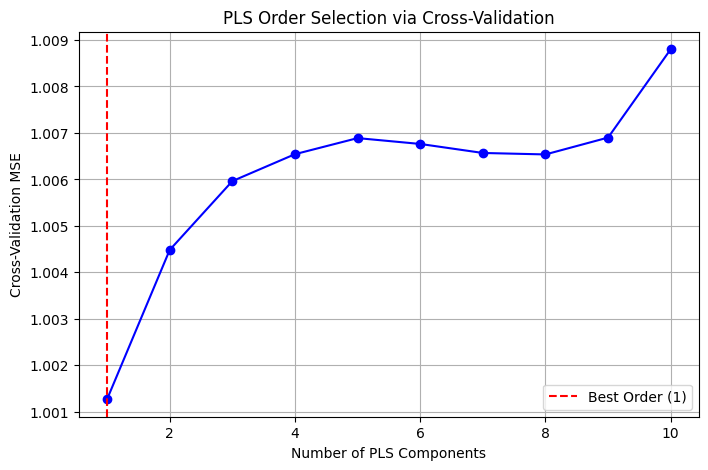

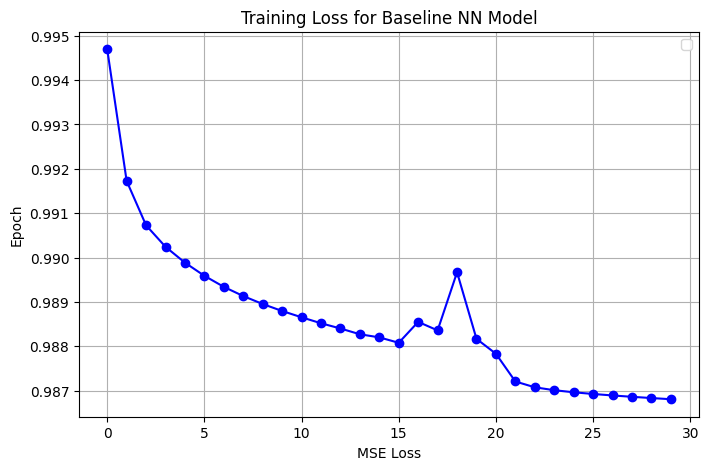

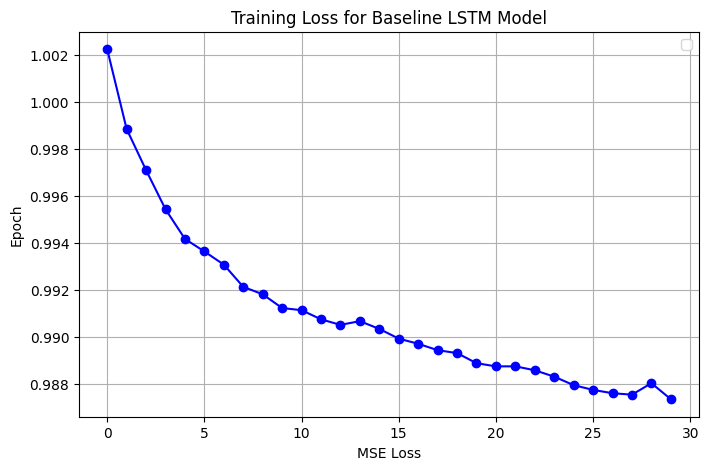

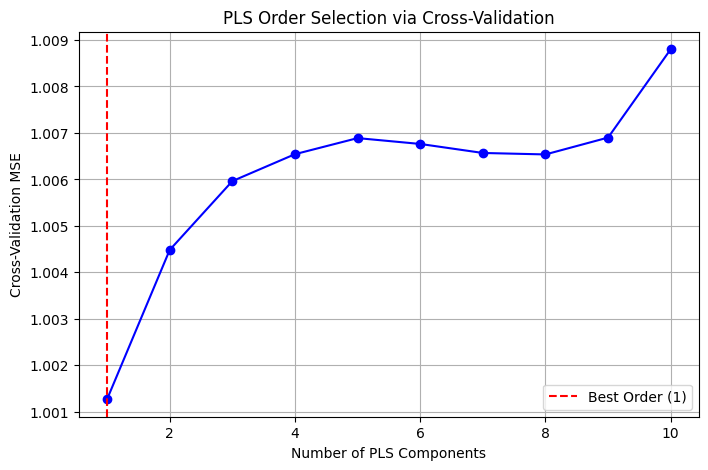

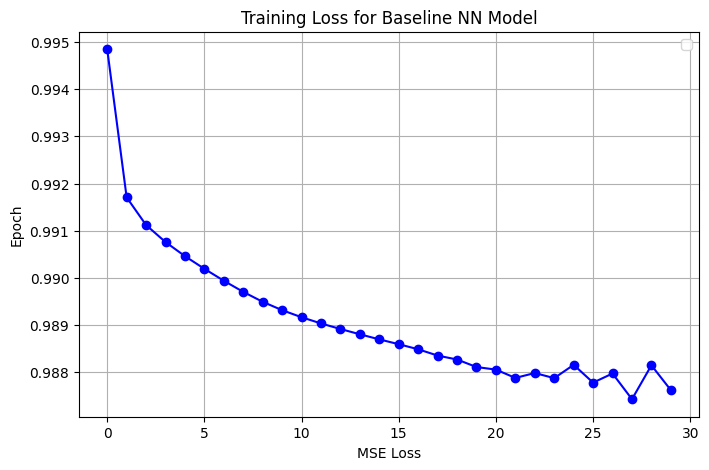

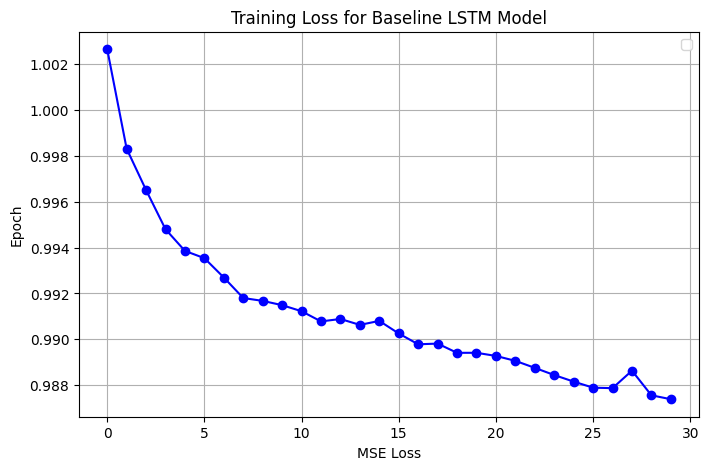

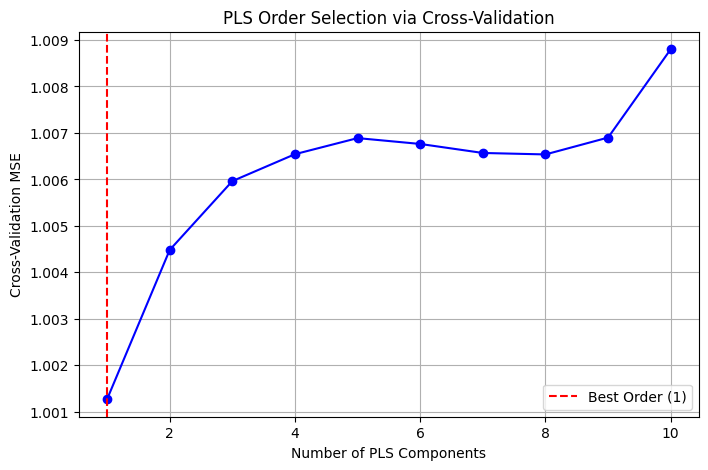

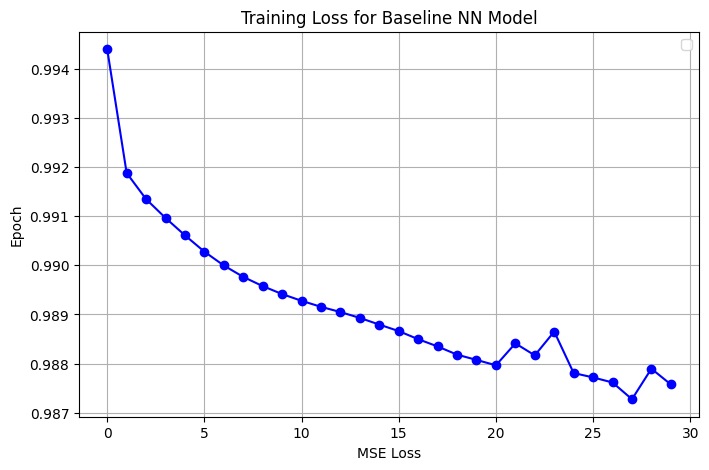

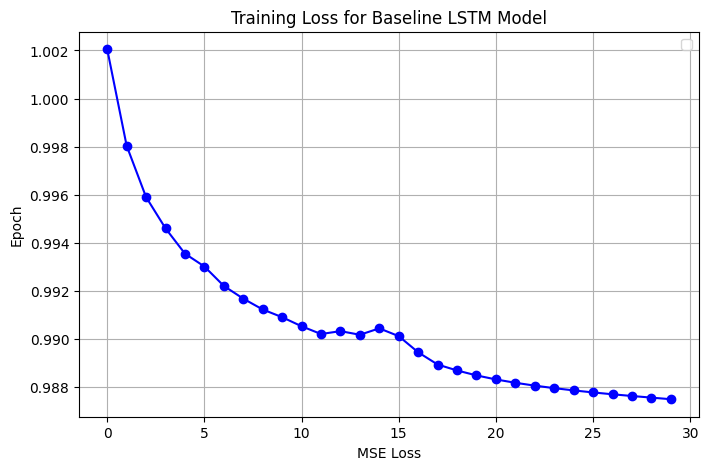

In [3]:
config = ModelConfig()
securities = ['SPY']
for sec in securities:
    logger.info(f"##########{sec}############")
    predictor = Predictor(config, sec)
    #predictor.df.to_csv("/kaggle/working/dataDf.csv", index=False)
    predictor.train_model()
    predictor.predict()
    
    config.learned_volatility_gate = True
    predictor3 = Predictor(config, sec)
    predictor3.train_model()
    predictor3.predict()
    
    config.n_regimes = 1
    config.learned_volatility_gate = False
    predictor2 = Predictor(config, sec)
    #predictor.df.to_csv("/kaggle/working/dataDf.csv", index=False)
    predictor2.train_model()
    predictor2.predict()
    